In [1]:
# Zachary Katz
# zachary_katz@mines.edu
# 11 November 2026

"""
Programatically download n tracks of SWOT L3_LR_SSH_Expert data for all available
cycles, clean, and calculate tides in an harmonic inversion.
"""

# Imports
import altimetry_downloader_aviso
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from utide import solve
import matplotlib.dates as mdates
from joblib import Parallel, delayed

In [7]:
import pyTMD
model_dir = "/mnt/c/Users/ZacharyKatz/Desktop/Research/Background/GOT5.6"    
model_name = "GOT5.6"
m = pyTMD.io.model(model_dir).from_database(model_name)
print(m)      
ds = m.open_dataset(group="z")

pyTMD.io.model
    name: GOT5.6


In [30]:
# Plot GOT for 8 constitutents on 1 degree grid
constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
names = [c.lower() for c in constits]
def got_constants(lon, lat, names, batch=20000):
    """Pointwise interpolation. Returns amp (m) and Greenwich phase (deg), shape (n_const, n_points)."""
    n = lon.size
    amp = np.full((len(names), n), np.nan)
    ph = np.full((len(names), n), np.nan)
    for s in range(0, n, batch):
        sl = slice(s, min(s + batch, n))
        x = xr.DataArray(lon[sl], dims="points")
        y = xr.DataArray(lat[sl], dims="points")
        local = ds.tmd.interp(x, y, extrapolate=True)
        hc = np.stack([np.asarray(local[c].values) for c in names])
        assert hc.shape == (len(names), sl.stop - sl.start), hc.shape   # catches the grid case early
        amp[:, sl] = np.abs(hc)
        ph[:, sl] = np.degrees(np.arctan2(-hc.imag, hc.real)) % 360
    return amp, ph

lon = np.arange(-180, 180, 1)
lat = np.arange(-90, 90, 1)
grid = np.meshgrid(lon, lat)
lon_raveled = grid[0].ravel()
lat_raveled = grid[1].ravel()


amp, ph = got_constants(lon_raveled, lat_raveled, names)
    

In [31]:

def get_spilhaus_mask(lon2d, lat2d, projection):
    # Transform geographic coordinates into Spilhaus coordinates
    xy = projection.transform_points(
        ccrs.PlateCarree(), lon2d, lat2d
    )
    x = xy[..., 0]
    y = xy[..., 1]

    bound = np.mean(np.abs(np.asarray(projection.bounds)))

    # Identify points near the projection boundary
    near_bound = (
        (np.abs(x) > 0.95 * bound) |
        (np.abs(y) > 0.95 * bound)
    )

    # Rotate coordinates to align with the projection boundary
    theta = np.deg2rad(45)
    rot_x = x * np.cos(theta) - y * np.sin(theta)
    rot_y = y * np.cos(theta) + x * np.sin(theta)

    # Detect sign changes across cell diagonals
    change_sign0 = (
        (rot_x[1:, 1:] * rot_x[:-1, :-1] < 0) |
        (rot_y[1:, 1:] * rot_y[:-1, :-1] < 0)
    )

    change_sign1 = (
        (rot_x[1:, :-1] * rot_x[:-1, 1:] < 0) |
        (rot_y[1:, :-1] * rot_y[:-1, 1:] < 0)
    )

    change_sign = change_sign0 | change_sign1

    # Expand the mask to all four corners of affected cells
    sign_change = np.zeros_like(x, dtype=bool)

    sign_change[1:, 1:] |= change_sign
    sign_change[:-1, :-1] |= change_sign
    sign_change[1:, :-1] |= change_sign
    sign_change[:-1, 1:] |= change_sign

    return near_bound & sign_change

Plotting M2
Plotting S2
Plotting N2
Plotting K2
Plotting K1
Plotting O1
Plotting P1
Plotting Q1


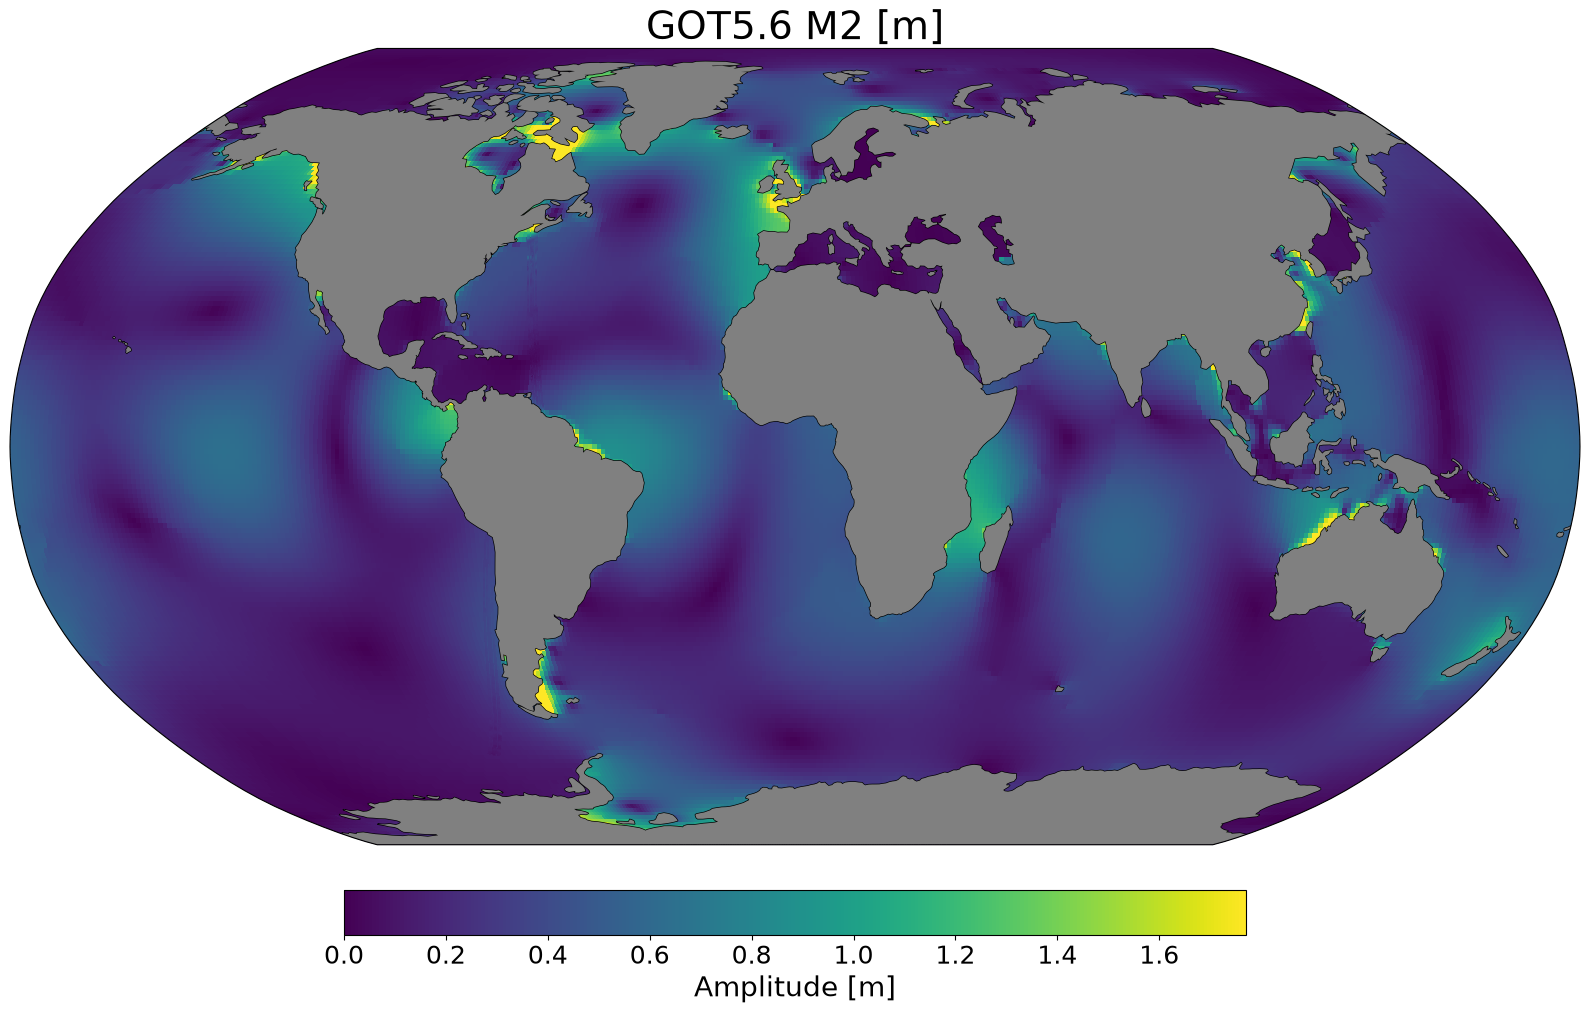

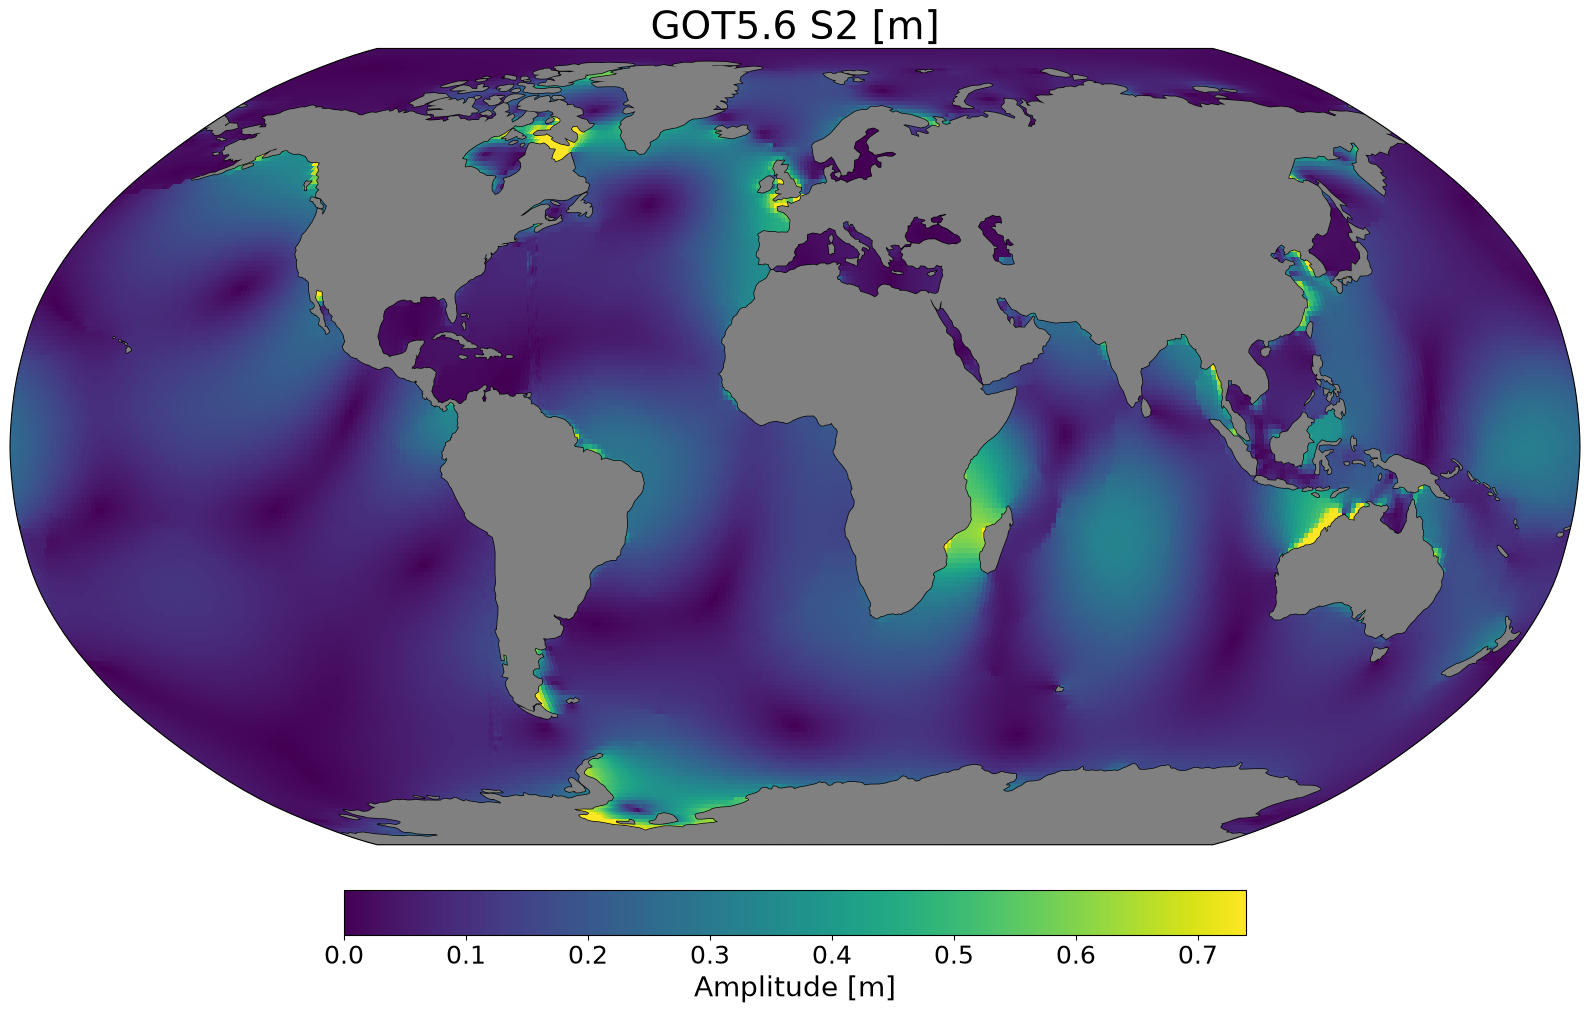

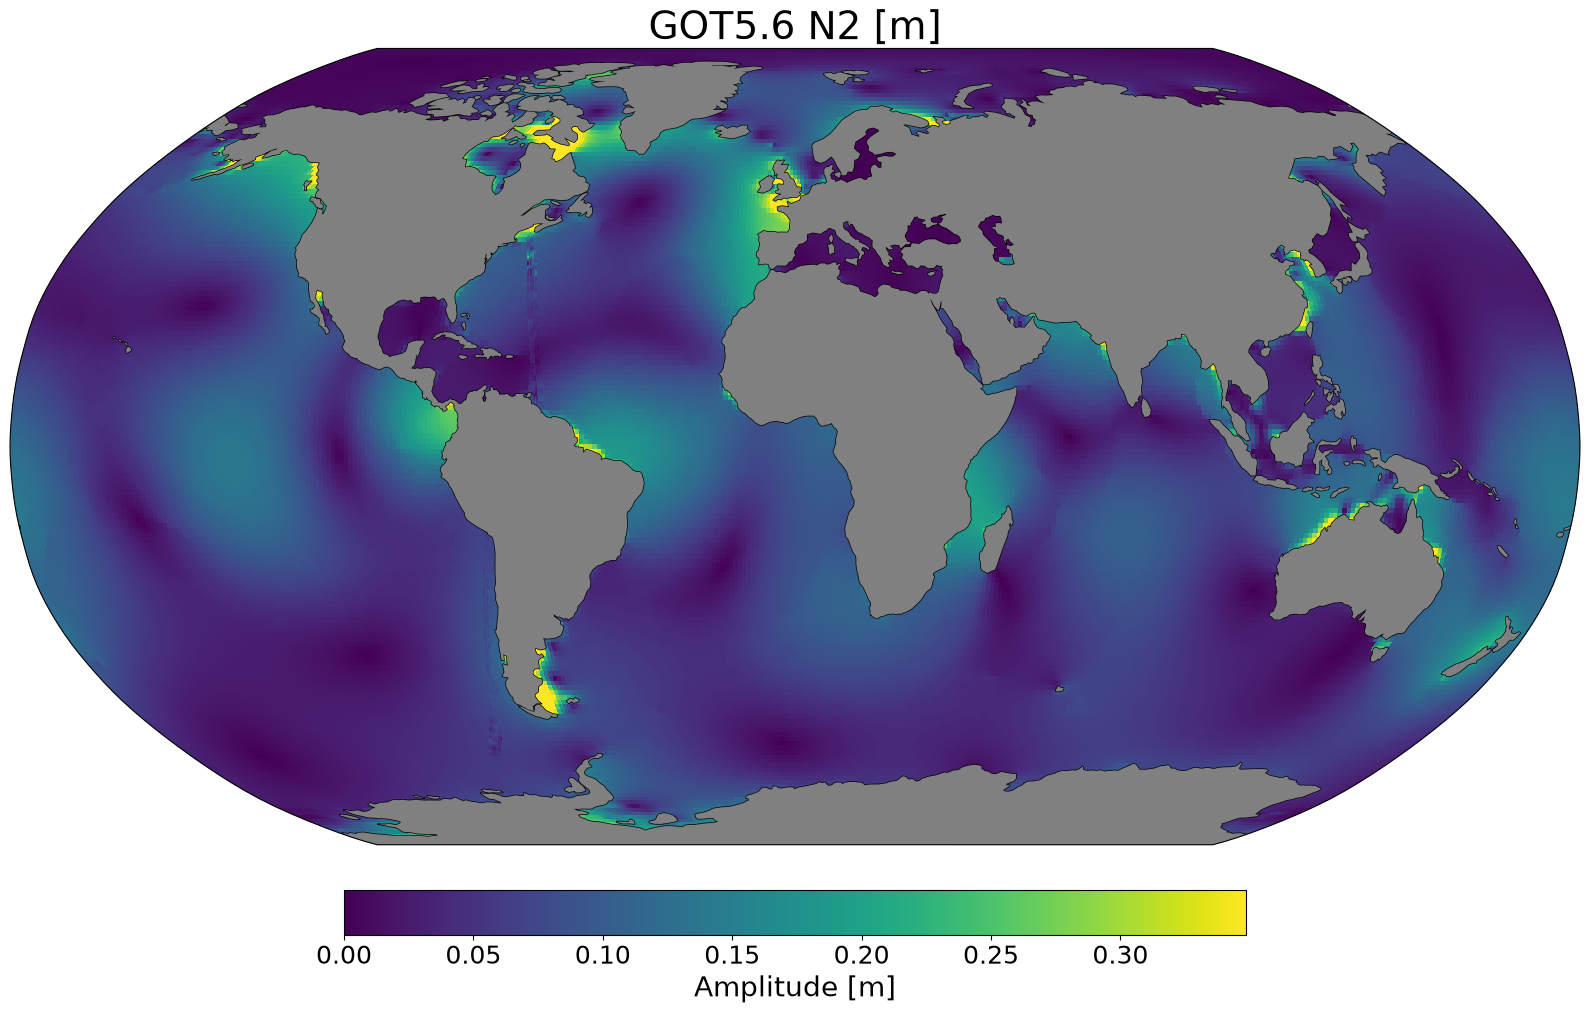

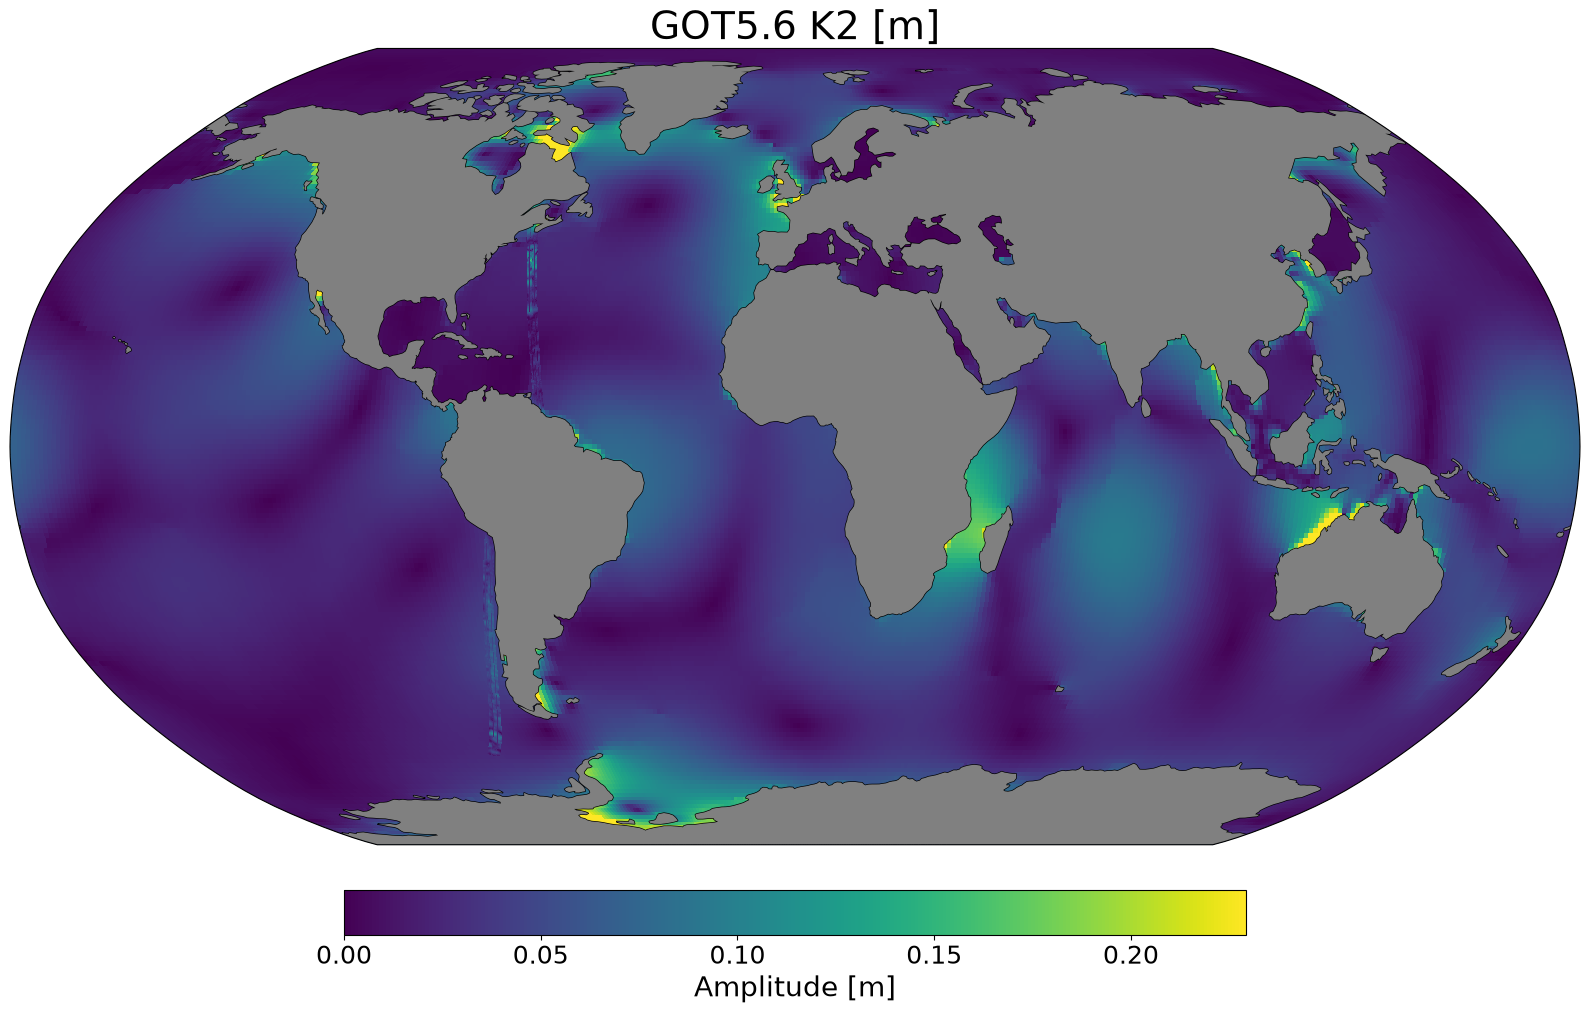

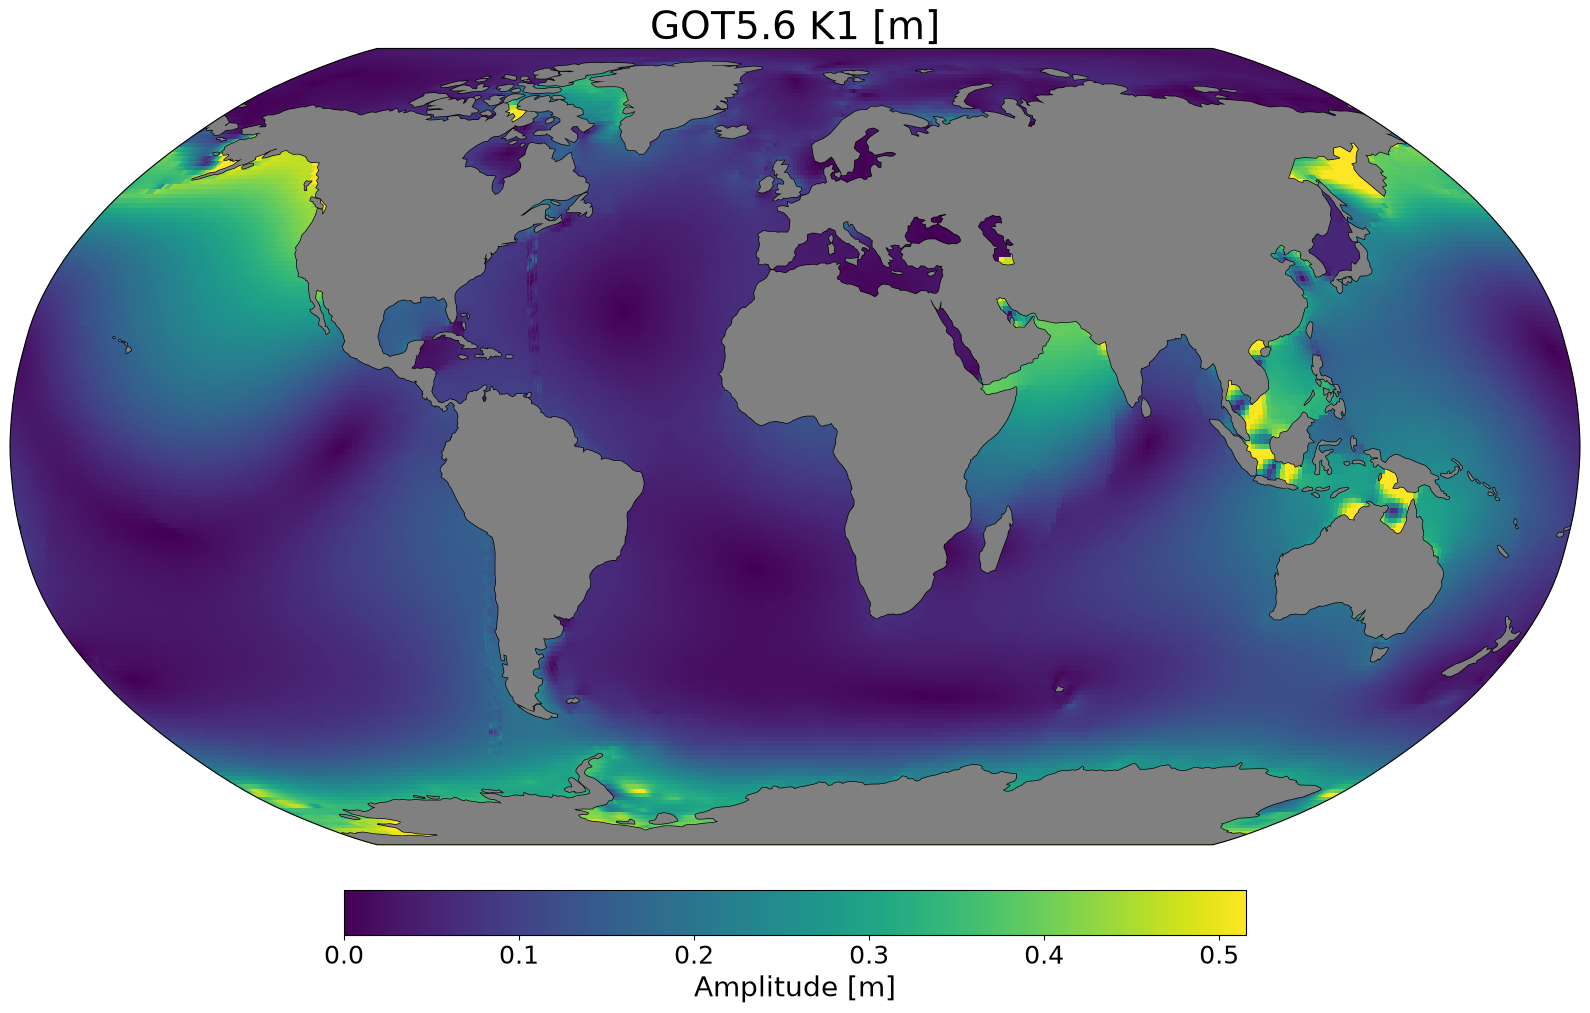

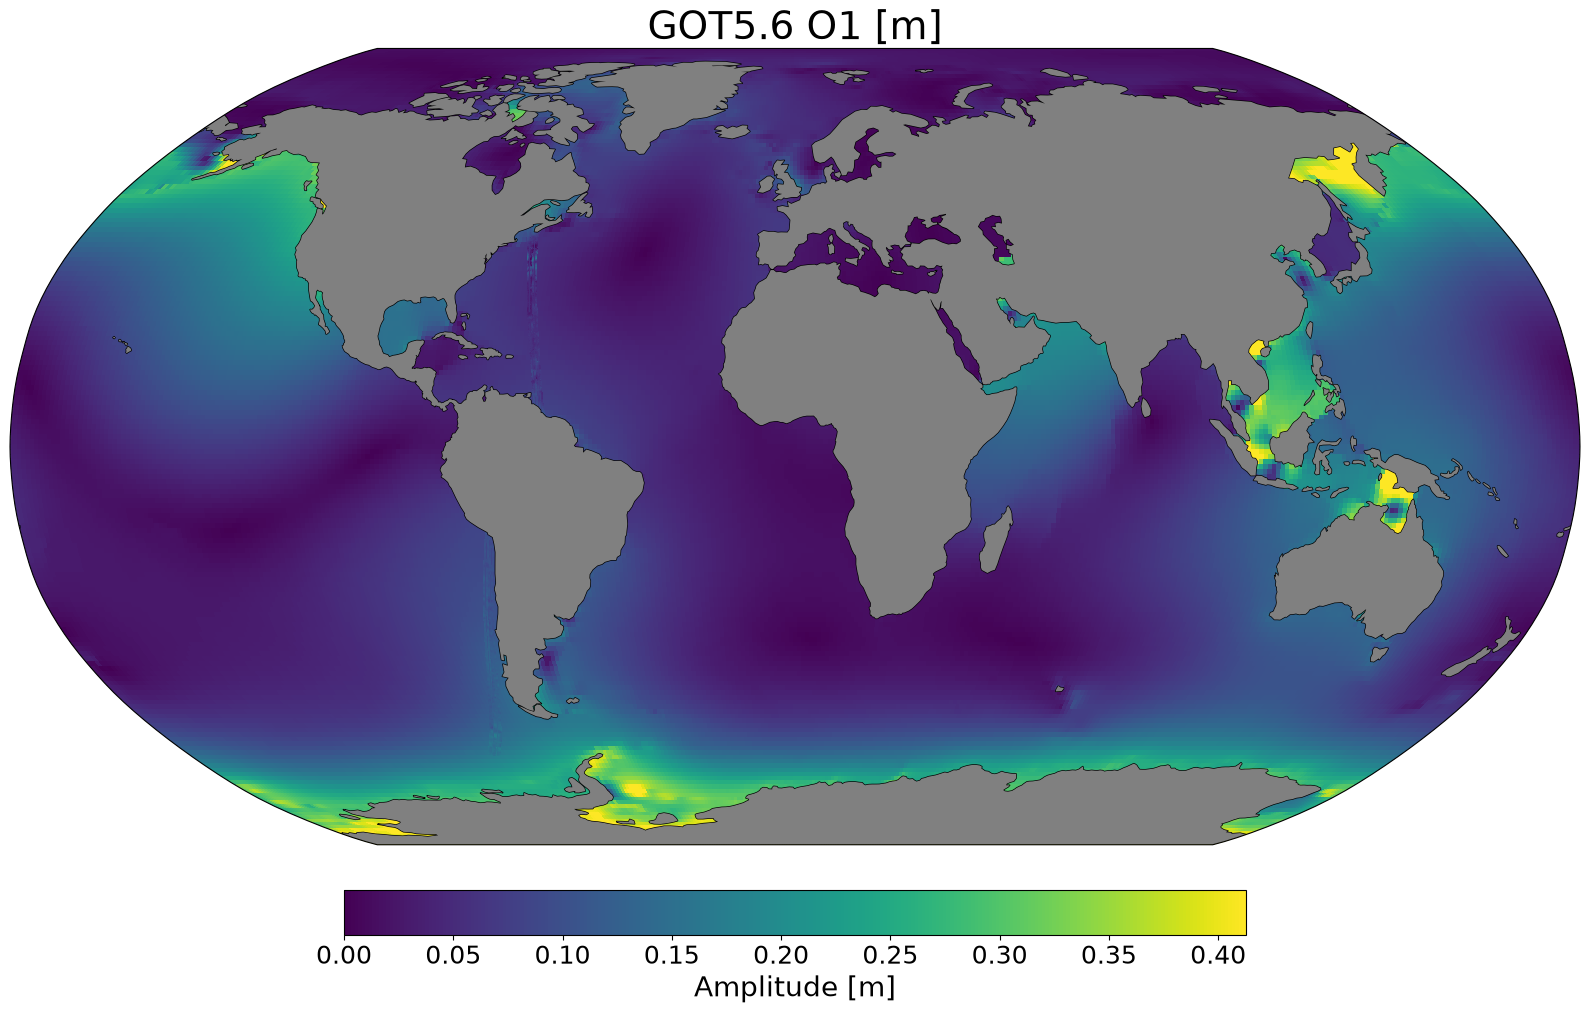

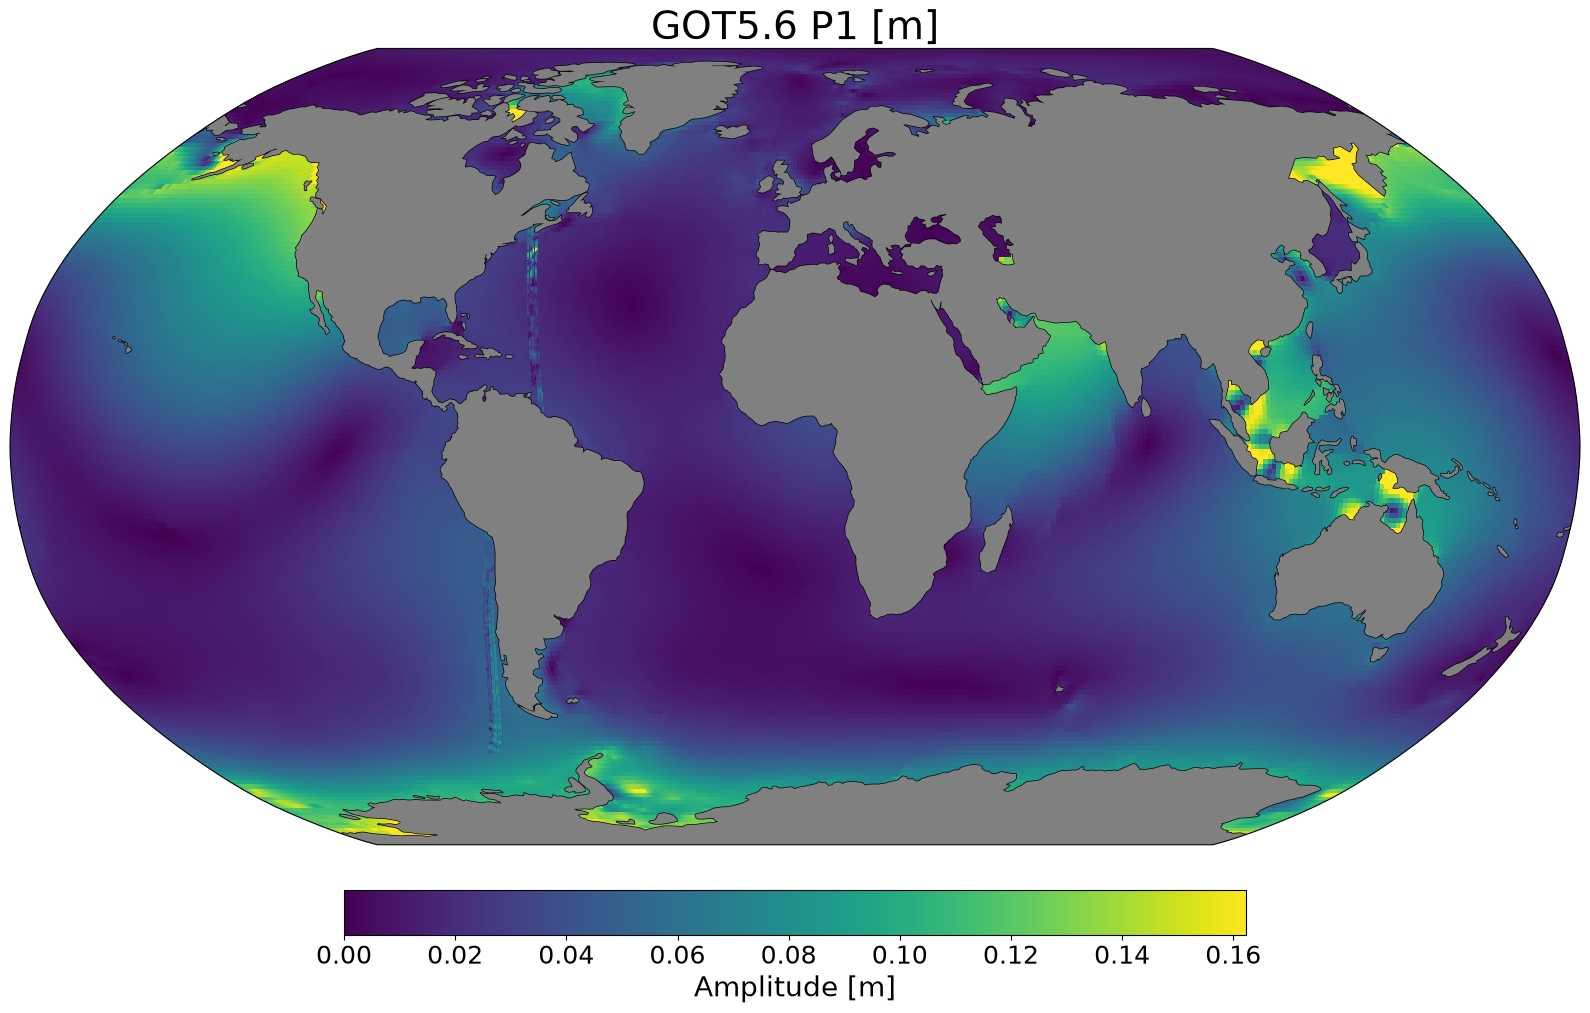

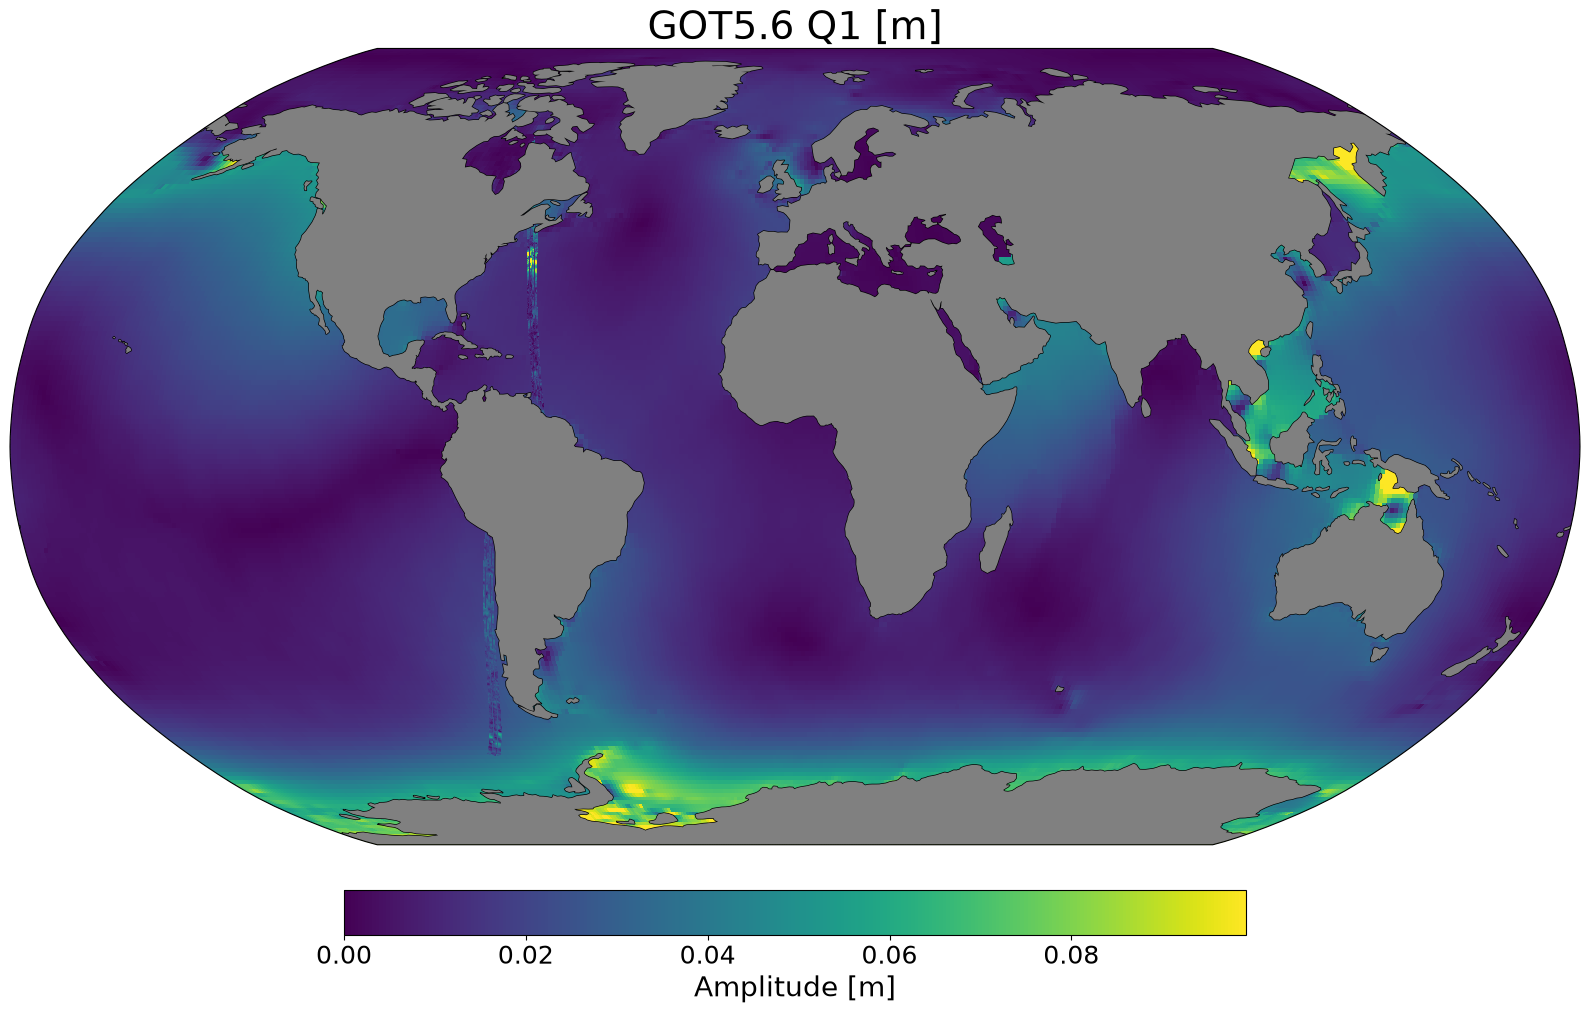

In [33]:
projection = "robinson"
#projection = "spilhaus"

constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
for constituent in constits[:]:
    print(f"Plotting {constituent}")
    if projection == "spilhaus":
        fig_got, ax = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Spilhaus()})
    elif projection == "robinson":
        fig_got, ax = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Robinson()})
    title = f"GOT5.6 {constituent} [m]"
    cmap = "viridis"

    # Get 98th percentile for colorbar limits
    k = constits.index(constituent)
    amp_got = amp[k, :]
    limit = (0, np.nanpercentile(amp_got, 98))

    if projection == "spilhaus":
        mask = get_spilhaus_mask(lon_raveled, lat_raveled, ccrs.Spilhaus())
        amp_got = np.ma.masked_where(mask, amp_got)
    
    amp_got = amp_got.reshape((lat.size, lon.size))

    ax.pcolormesh(
        lon,
        lat,
        amp_got,
        cmap=cmap,
        vmin=limit[0],
        vmax=limit[1],
        shading="auto",
        transform=ccrs.PlateCarree(),
        rasterized=True
    )

    # Plot SWOT on top
    swot_dfs = sorted(Path("./_Data").glob("swot_tide_fit_pass_*.nc"))
    for df_path in swot_dfs:
        swot_df = xr.open_dataset(df_path)
        lon_swot = swot_df["longitude"].values
        lat_swot = swot_df["latitude"].values

        variables = [
            swot_df["amplitude"].isel(constituent=k).values,
            swot_df["amp_got"].isel(constituent=k).values,
            swot_df["vec"].isel(constituent=k).values
        ]
                
        for i, v in enumerate(variables):
            valid = (
                np.isfinite(v)
                & np.isfinite(lon_swot)
                & np.isfinite(lat_swot)
            )
            v = np.where(valid, v, np.nan)
            variables[i] = v


            sc = ax.pcolormesh(
                lon_swot,
                lat_swot,
                swot_df["amplitude"].isel(constituent=k).values,
                cmap=cmap,
                vmin=limit[0],
                vmax=limit[1],
                shading="auto",
                transform=ccrs.PlateCarree(),
                rasterized=True
            )

    ax.coastlines()
    ax.add_feature(
        cfeature.LAND,
        facecolor="gray",
        edgecolor="none",
        zorder=2
    )
    ax.set_title(title, fontsize=28)
    sm = plt.cm.ScalarMappable(
        norm=plt.Normalize(*limit),
        cmap=cmap
    )
    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        pad=0.05,
        fraction=0.05
    )
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Amplitude [m]", fontsize=20)

    if projection == "spilhaus":
        ax.set_global()
    elif projection == "robinson":
        ax.set_global()

    fig_got.tight_layout()
    fig_got.savefig(f"./GOT_{constituent}", dpi=300)